In [ ]:
from pathlib import Path
import os

# notebooks live in ai/notebooks/; data paths are relative to ai/
os.chdir(Path("..").resolve())


# intensity EDA

Compare real vs each attack using pixel intensity:

- histograms
- Kolmogorov–Smirnov (KS) on per-image mean intensity
- Cohen's d on the same means

Uses `metadata/manifest.csv`. Sample is fixed with seed 42 so re-running gives the same numbers.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image
from scipy import stats

SEED = 42
N_SAMPLE = 500
rng = np.random.default_rng(SEED)

manifest = pd.read_csv("metadata/manifest.csv")
attacks = ["gaussian_noise", "gamma", "copy_region", "lesion_insert", "jpeg"]
manifest.label.value_counts(), manifest.attack.value_counts()

(label
 fake    29880
 real     7200
 Name: count, dtype: int64,
 attack
 none              7200
 gaussian_noise    7200
 gamma             7200
 copy_region       7200
 lesion_insert     7200
 jpeg              1080
 Name: count, dtype: int64)

In [2]:
def load_gray(path):
    return np.asarray(Image.open(path).convert("L"), dtype=np.float32)


def mean_intensity(path):
    return float(load_gray(path).mean())


def sample_pairs(attack, n=N_SAMPLE):
    fake = manifest[(manifest.attack == attack) & (manifest.label == "fake")].copy()
    if len(fake) > n:
        fake = fake.sample(n=n, random_state=SEED)
    # paired real path is source_path
    rows = []
    for _, row in fake.iterrows():
        rows.append({
            "attack": attack,
            "real_path": row.source_path,
            "fake_path": row.path,
            "held_out": bool(row.held_out),
        })
    return pd.DataFrame(rows)


pairs = pd.concat([sample_pairs(a) for a in attacks], ignore_index=True)
pairs.groupby("attack").size()

attack
copy_region       500
gamma             500
gaussian_noise    500
jpeg              500
lesion_insert     500
dtype: int64

In [3]:
def cohens_d(a, b):
    a = np.asarray(a, dtype=np.float64)
    b = np.asarray(b, dtype=np.float64)
    na, nb = len(a), len(b)
    va, vb = a.var(ddof=1), b.var(ddof=1)
    pooled = np.sqrt(((na - 1) * va + (nb - 1) * vb) / (na + nb - 2))
    if pooled == 0:
        return 0.0
    return float((a.mean() - b.mean()) / pooled)


stats_rows = []
means = {}

for attack in attacks:
    sub = pairs[pairs.attack == attack]
    real_means = np.array([mean_intensity(p) for p in sub.real_path], dtype=np.float64)
    fake_means = np.array([mean_intensity(p) for p in sub.fake_path], dtype=np.float64)
    means[attack] = (real_means, fake_means)

    ks = stats.ks_2samp(real_means, fake_means)
    d = cohens_d(real_means, fake_means)
    stats_rows.append({
        "attack": attack,
        "n": len(sub),
        "real_mean": float(real_means.mean()),
        "fake_mean": float(fake_means.mean()),
        "real_std": float(real_means.std(ddof=1)),
        "fake_std": float(fake_means.std(ddof=1)),
        "ks_stat": float(ks.statistic),
        "ks_pvalue": float(ks.pvalue),
        "cohens_d": d,
        "held_out": bool(sub.held_out.iloc[0]),
    })
    print(attack, "KS", round(ks.statistic, 4), "p", f"{ks.pvalue:.2e}", "d", round(d, 3))

intensity_stats = pd.DataFrame(stats_rows)
intensity_stats.to_csv("eda/intensity_stats.csv", index=False)
intensity_stats

gaussian_noise KS 0.122 p 1.16e-03 d -0.147


gamma KS 0.316 p 1.84e-22 d -0.233


copy_region KS 0.016 p 1.00e+00 d -0.003


lesion_insert KS 0.024 p 9.99e-01 d -0.012


jpeg KS 0.02 p 1.00e+00 d -0.012


,attack,n,real_mean,fake_mean,real_std,fake_std,ks_stat,ks_pvalue,cohens_d,held_out
0,gaussian_noise,500,48.090001,50.726038,18.418280,17.367175,0.122,1.159308e-03,-0.147261,False
1,gamma,500,48.090001,54.820626,18.418280,36.457696,0.316,1.837791e-22,-0.233035,False
2,copy_region,500,48.090001,48.142779,18.418280,18.477629,0.016,1.000000e+00,-0.002861,False
3,lesion_insert,500,48.090001,48.316172,18.418280,18.274445,0.024,9.987737e-01,-0.012328,False
4,jpeg,500,47.030089,47.234160,17.650342,17.569926,0.020,9.999670e-01,-0.011588,True


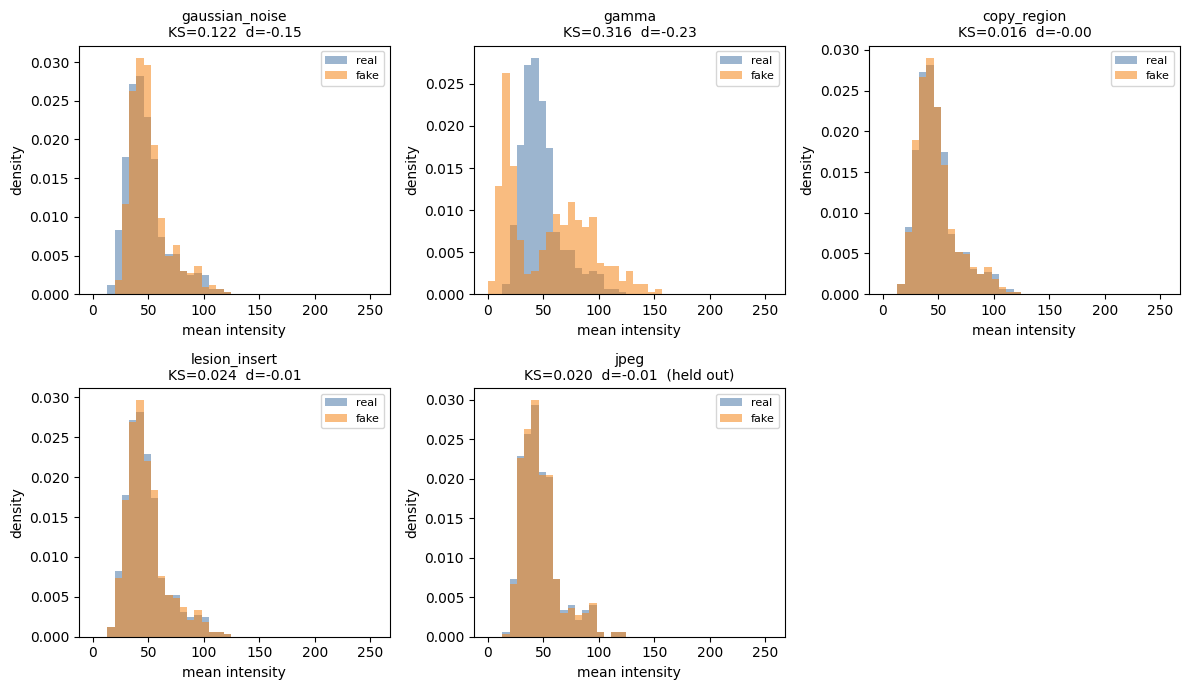

In [4]:
# histograms of per-image mean intensity
fig, axes = plt.subplots(2, 3, figsize=(12, 7))
axes = axes.ravel()

for i, attack in enumerate(attacks):
    real_m, fake_m = means[attack]
    ax = axes[i]
    bins = np.linspace(0, 255, 40)
    ax.hist(real_m, bins=bins, alpha=0.55, label="real", color="#4c78a8", density=True)
    ax.hist(fake_m, bins=bins, alpha=0.55, label="fake", color="#f58518", density=True)
    row = intensity_stats[intensity_stats.attack == attack].iloc[0]
    title = f"{attack}\nKS={row.ks_stat:.3f}  d={row.cohens_d:.2f}"
    if row.held_out:
        title += "  (held out)"
    ax.set_title(title, fontsize=10)
    ax.set_xlabel("mean intensity")
    ax.set_ylabel("density")
    ax.legend(fontsize=8)

axes[-1].axis("off")
plt.tight_layout()
Path("eda").mkdir(exist_ok=True)
plt.savefig("eda/intensity_mean_histograms.png", dpi=140, bbox_inches="tight")
plt.show()

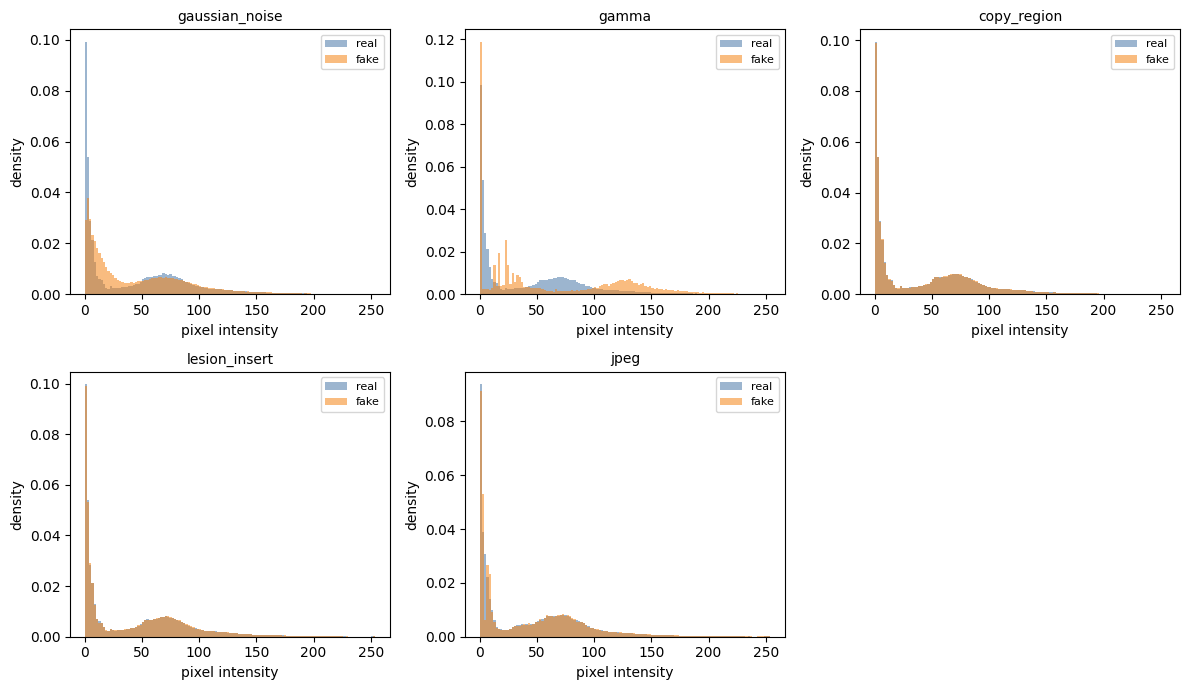

In [5]:
# pixel-level histograms from a smaller image sample (visual only)
N_PIXEL_IMGS = 40
fig, axes = plt.subplots(2, 3, figsize=(12, 7))
axes = axes.ravel()

for i, attack in enumerate(attacks):
    sub = pairs[pairs.attack == attack].sample(n=min(N_PIXEL_IMGS, len(pairs[pairs.attack == attack])), random_state=SEED)
    real_pix = np.concatenate([load_gray(p).ravel() for p in sub.real_path])
    fake_pix = np.concatenate([load_gray(p).ravel() for p in sub.fake_path])
    # subsample pixels so the plot stays light
    real_pix = rng.choice(real_pix, size=min(200_000, len(real_pix)), replace=False)
    fake_pix = rng.choice(fake_pix, size=min(200_000, len(fake_pix)), replace=False)

    ax = axes[i]
    bins = np.arange(0, 256, 2)
    ax.hist(real_pix, bins=bins, alpha=0.55, label="real", color="#4c78a8", density=True)
    ax.hist(fake_pix, bins=bins, alpha=0.55, label="fake", color="#f58518", density=True)
    ax.set_title(attack, fontsize=10)
    ax.set_xlabel("pixel intensity")
    ax.set_ylabel("density")
    ax.legend(fontsize=8)

axes[-1].axis("off")
plt.tight_layout()
plt.savefig("eda/intensity_pixel_histograms.png", dpi=140, bbox_inches="tight")
plt.show()

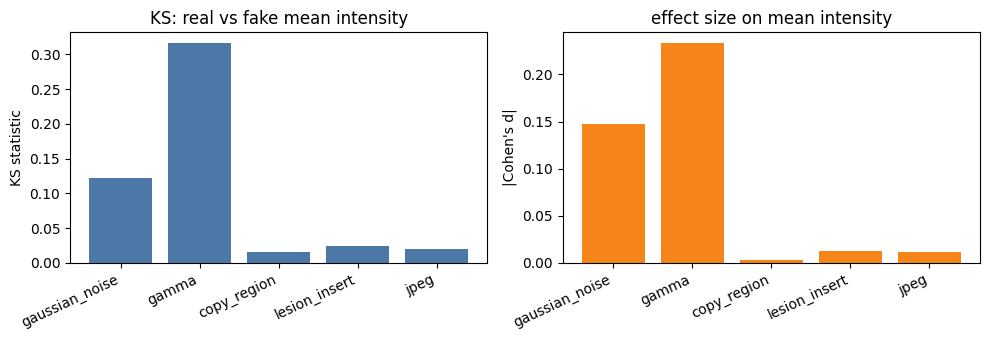

saved eda_intensity_stats.csv and plots under eda/


,attack,ks_stat,ks_pvalue,cohens_d,held_out
0,gaussian_noise,0.122,1.159308e-03,-0.147261,False
1,gamma,0.316,1.837791e-22,-0.233035,False
2,copy_region,0.016,1.000000e+00,-0.002861,False
3,lesion_insert,0.024,9.987737e-01,-0.012328,False
4,jpeg,0.020,9.999670e-01,-0.011588,True


In [6]:
# bar chart: KS statistic and |Cohen's d|
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))

x = np.arange(len(intensity_stats))
labels = intensity_stats.attack.tolist()

axes[0].bar(x, intensity_stats.ks_stat, color="#4c78a8")
axes[0].set_xticks(x)
axes[0].set_xticklabels(labels, rotation=25, ha="right")
axes[0].set_ylabel("KS statistic")
axes[0].set_title("KS: real vs fake mean intensity")

axes[1].bar(x, intensity_stats.cohens_d.abs(), color="#f58518")
axes[1].set_xticks(x)
axes[1].set_xticklabels(labels, rotation=25, ha="right")
axes[1].set_ylabel("|Cohen's d|")
axes[1].set_title("effect size on mean intensity")

plt.tight_layout()
plt.savefig("eda/intensity_ks_cohens_d.png", dpi=140, bbox_inches="tight")
plt.show()

print("saved eda/intensity_stats.csv and plots under eda/")
intensity_stats[["attack", "ks_stat", "ks_pvalue", "cohens_d", "held_out"]]

## Intensity-Based EDA: What We Found and What to Do Next

In this analysis, we compared real medical images with their manipulated versions to see whether the attacks change the overall intensity of the images. We used 500 pairs per attack, selected with `seed=42`, and compared the mean intensity of real and fake images using the KS statistic and Cohen's d. We also plotted the intensity distributions to get a clearer picture of the differences.

The results are saved in `eda/intensity_stats.csv`, and the plots are available in the `eda/` folder.

### 1. Results

| Attack | Real Mean | Fake Mean | KS | p-value | Cohen's d |
|---|---:|---:|---:|---:|---:|
| Gaussian Noise | 48.09 | 50.73 | 0.122 | 0.00116 | -0.147 |
| Gamma | 48.09 | 54.82 | 0.316 | Very small | -0.233 |
| Copy Region | 48.09 | 48.14 | 0.016 | Approximately 1 | -0.003 |
| Lesion Insert | 48.09 | 48.32 | 0.024 | Approximately 1 | -0.012 |
| JPEG | 47.03 | 47.23 | 0.020 | Approximately 1 | -0.012 |

*Note: JPEG uses images from the held-out test split, which explains the slightly different real-image mean.*

### 2. What the results tell us

**Gamma has the clearest difference in intensity distribution.**

The mean intensity increases from 48.09 for real images to 54.82 for fake images. It also has the highest KS value (0.316) and the largest absolute Cohen's d among the attacks we tested.

One possible explanation is how the gamma attack is applied. Since it randomly uses different gamma values, some images may become darker while others become brighter. This can make the fake-image distribution more spread out instead of simply shifting all images in the same direction.

**Gaussian noise also changes the intensity distribution, but the difference is smaller.**

The mean increases from 48.09 to 50.73, and the KS statistic is 0.122. The reported p-value suggests a statistically significant difference, although the effect size is small.

This means intensity statistics may provide some useful information about noise manipulation, but the overlap between real and fake images could still make classification difficult.

**Copy Region, Lesion Insert, and JPEG show almost no difference in global mean intensity.**

Their KS values are all below 0.025, and their Cohen's d values are close to zero. In other words, these attacks do not appear to change the overall intensity distribution very much under the current analysis.

This makes sense for some types of manipulation. Copying a region or inserting a lesion may affect only a small part of an image, so the change can get lost when we calculate one mean value for the entire image. JPEG compression can also introduce artifacts without noticeably changing the global mean.

This does not mean these images are unchanged or impossible to detect. It only means that global intensity statistics are not enough to describe their differences.

### 3. What KS and Cohen's d add to the analysis

The two metrics help us look at the results from different angles.

The KS statistic compares the distributions of real and fake image means. A larger value indicates a greater difference between the distributions.

Cohen's d measures the difference between the two means relative to the variability in the data. Since we calculate it as real mean minus fake mean, a negative value means that fake images have a higher average intensity.

The p-value helps us assess whether the observed difference provides evidence against the assumption that the two distributions are the same. A small p-value does not tell us how accurately a model can detect fake images, and a large p-value does not prove that the distributions are identical.

One important observation is that gamma has the largest KS value, but its Cohen's d is still relatively small. This suggests that the difference is not just about the two averages; the overall shape and spread of the distributions also matter.

### 4. What we saw in the histograms

The mean-intensity histograms show the distribution of one value per image, while the pixel-intensity histograms show the distribution of pixel values themselves.

The clearest separation appears in the gamma results, followed by Gaussian noise. The other attacks have much more overlap in the global intensity measurements.

Looking at individual pixel values can reveal differences that are not obvious from the mean alone. However, a pixel histogram does not preserve the location of each pixel. Two images can have similar histograms even if some of their regions have been rearranged or modified.

This is particularly relevant to copy-region manipulation and lesion insertion, where the location and shape of the changed region may matter more than the overall brightness.

### 5. What we should do next

Based on these results, I would keep intensity analysis as a useful starting point, but I would not use it as the main approach for detecting tampering.

The next steps should focus on features that capture differences beyond global brightness:

- **Copy Region and Lesion Insert:** Explore local texture, patch-level features, boundaries, and spatial inconsistencies that might reveal modified regions.
- **Gaussian Noise:** Examine noise patterns and image residuals to see whether they provide a stronger signal than mean intensity.
- **JPEG:** Investigate compression artifacts and frequency-based features.
- **All attacks:** Keep the evaluation separate for each attack type so we can see which manipulations the model handles well and which remain difficult.

We should also establish a simple baseline before moving to more complex models. This will give us something reliable to compare against when testing additional features or a CNN.

The next analysis could look at frequency information using FFT and local image statistics. These experiments would help us decide whether hand-crafted features add useful information before moving further into deep learning.

### 6. Things to check before drawing final conclusions

There are a few points we should verify before relying too heavily on these results:

- Recheck the KS statistics and p-values against the actual samples and the implementation used to calculate them.
- Confirm that each real image is correctly matched with its manipulated version.
- Account for the paired nature of the data when choosing statistical tests.
- Make sure related images from the same original source do not appear across training, validation, and test sets.
- Check the JPEG sample separately because it comes from the held-out test split and has a smaller sample count.
- Consider correcting for multiple statistical tests when interpreting p-values across the five attacks.
- Evaluate all future models on held-out source images and report precision, recall, F1-score, and other appropriate metrics for each attack.

These checks matter because a difference in an EDA plot does not automatically translate into good detection performance on unseen images.

### Conclusion

The main takeaway is that gamma and Gaussian noise leave more noticeable changes in global intensity statistics, while copy-region manipulation, lesion insertion, and JPEG compression do not show the same pattern.

This gives us a useful starting point for the project. Instead of relying on brightness alone, we should investigate local, spatial, and frequency-based features that may capture the changes missed by this analysis.

The next stage should focus on testing these ideas and comparing them against a baseline, while keeping the evaluation fair and checking performance separately for each attack.